# Scalar NSI with NeutrinoScalarNSI.jl

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JuliaNeutrino/NeutrinoScalarNSI.jl/blob/main/notebooks/01_scalar_NSI.ipynb)

If a light scalar couples to neutrinos and to the matter they cross, it does not add a potential the way vector NSI do. Instead it changes the neutrino **mass matrix**:

$$M = U\,\mathrm{diag}(m_1, m_2, m_3)\,U^\dagger \;\to\; M + \delta M, \qquad H = \frac{(M + \delta M)(M + \delta M)^\dagger}{2E} + V\,\mathrm{diag}(1, 0, 0).$$

NeutrinoScalarNSI.jl writes $\delta M_{\alpha\beta} = \sqrt{|\Delta m^2_{31}|}\;|\eta_{\alpha\beta}|\,e^{i\delta_{\alpha\beta}}$, the convention of Ge and Parke (arXiv:1812.08376). This has two consequences that this notebook explores:

- $\delta M$ adds to $M$ itself, not to $M M^\dagger$, so the effect depends on the **absolute** neutrino masses, which oscillations otherwise never see.
- The correction sits in the vacuum part of $H$ and scales like $1/E$, the same way as the masses.

The package is a *propagation block* for [GLoBES.jl](https://github.com/JuliaNeutrino/GLoBES.jl): probabilities, event rates, χ² and fits in GLoBES.jl treat the η's like any other parameter.

In [ ]:
# Install GLoBES.jl and NeutrinoScalarNSI.jl from GitHub, plus Plots (the first run takes a few minutes).
# On your own computer, skip this cell if they are already installed.
using Pkg
Pkg.add(url = "https://github.com/JuliaNeutrino/GLoBES.jl")
Pkg.add(url = "https://github.com/JuliaNeutrino/NeutrinoScalarNSI.jl")
Pkg.add("Plots")

In [1]:
using GLoBES, NeutrinoScalarNSI, Plots, LinearAlgebra
paper_theme!()   # Plots defaults for publication figures

## The whole package

`ScalarNSI` is a subtype of `GLoBES.PropagationBlock`. It differs from the vector-NSI block in two methods:

- `uses_absolute_masses` returns `true`, so GLoBES.jl builds $M$ from $m_1, m_2, m_3$ rather than from the mass splittings alone, and adds a parameter `m_lightest`.
- `mass_correction!` adds to δM where the vector block's `matter_correction!` adds to ε.

In [2]:
print(read(pathof(NeutrinoScalarNSI), String))

"""
Scalar non-standard neutrino interactions for GLoBES.jl: a correction to
the neutrino mass matrix from a light scalar, as a propagation block that
combines with the other blocks in `NewPhysics`.
"""
module NeutrinoScalarNSI

using GLoBES
using GLoBES:
    PropagationBlock,
    flavour_pairs,
    pair_label,
    coupling_parameters,
    coupling_aliases,
    add_couplings!
import GLoBES: block_parameters, parameter_aliases, uses_absolute_masses, mass_correction!

export ScalarNSI

"""
    ScalarNSI(couplings...; scale=:Δm31)

Scalar non-standard interactions: a correction δM to the neutrino mass
matrix, M → M + δM with δM_αβ = s |η_αβ| e^{iδ_αβ} (Hermitian), so that the
vacuum Hamiltonian is (M + δM)(M + δM)†/2E. The scale s is √|Δm²31| (the
convention of Ge and Parke, arXiv:1812.08376, and Medhi et al.) or a fixed
scale in eV.

Couplings are flavour pairs (`:ee`, `:eμ`, `:eτ`, `:μμ`, `:μτ`, `:ττ`, or
ASCII `:emu`, ...; all six by default). Parameters: `η_αβ` and, off the
diagonal, 

In [3]:
model = NewPhysics(ScalarNSI(:ee, :eμ, :eτ))
model.names   # m_lightest comes first: the block needs the absolute masses

6-element Vector{Symbol}:
 :m_lightest
 :η_ee
 :η_eμ
 :δ_eμ
 :η_eτ
 :δ_eτ

`ScalarNSI(...; scale = 0.05)` gives δM in units of 0.05 eV instead of $\sqrt{|\Delta m^2_{31}|}$. ASCII names (`eta_ee`, `delta_etau`, `mlightest`) work wherever parameters are named.

In [4]:
use_model!(model)   # the probability engine of everything in GLoBES.jl from now on
p = nufit_params("6.1")
sm = OscParams(model, p)
OscParams(model, p; eta_etau = 0.1, mlightest = 0.01) == OscParams(model, p; η_eτ = 0.1, m_lightest = 0.01)

true

## Appearance at DUNE

P(νμ → νe) over the 1300 km from Fermilab to SURF, with m_lightest = 0. The band follows η_eτ = 0.1 as its phase δ_eτ goes around the circle.

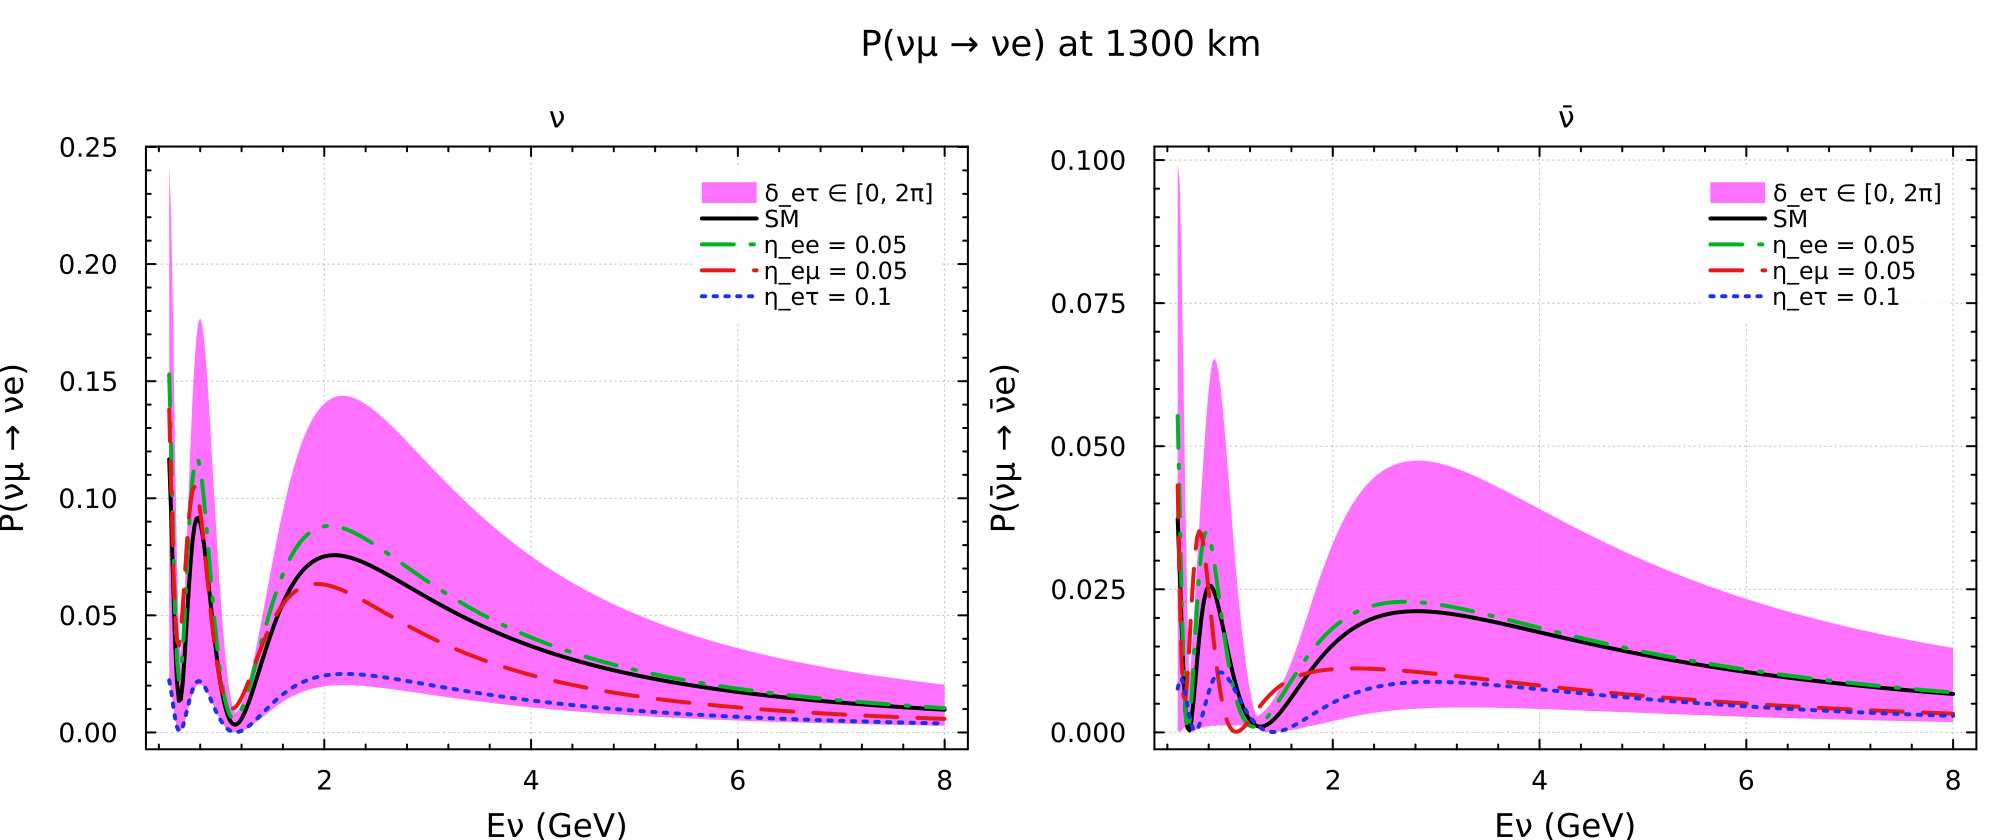

In [5]:
DUNE = (; L = 1300, ρ = 2.848)
E = range(0.5, 8, 400)
ηee = OscParams(model, p; η_ee = 0.05)
ηeμ = OscParams(model, p; η_eμ = 0.05)
ηeτ = OscParams(model, p; η_eτ = 0.1)
curves = ("SM" => sm, "η_ee = 0.05" => ηee, "η_eμ = 0.05" => ηeμ, "η_eτ = 0.1" => ηeτ)
band = ("δ_eτ ∈ [0, 2π]" => (ηeτ, :δ_eτ => range(0, 2π, 37)),)
panel(anti) = plot_probability(curves...; E, DUNE..., antineutrino = anti, bands = band)
plot_grid([panel(false) panel(true)]; title = "P(νμ → νe) at 1300 km", column_titles = ("ν", "ν̄"), size = (1000, 420))

## Oscillations that see the absolute mass scale

Standard oscillations depend only on $\Delta m^2_{ij}$, so with η = 0 the lightest mass drops out. With scalar NSI it does not: $(M + \delta M)(M + \delta M)^\dagger$ contains the cross term $M\,\delta M^\dagger$, which grows with the masses.

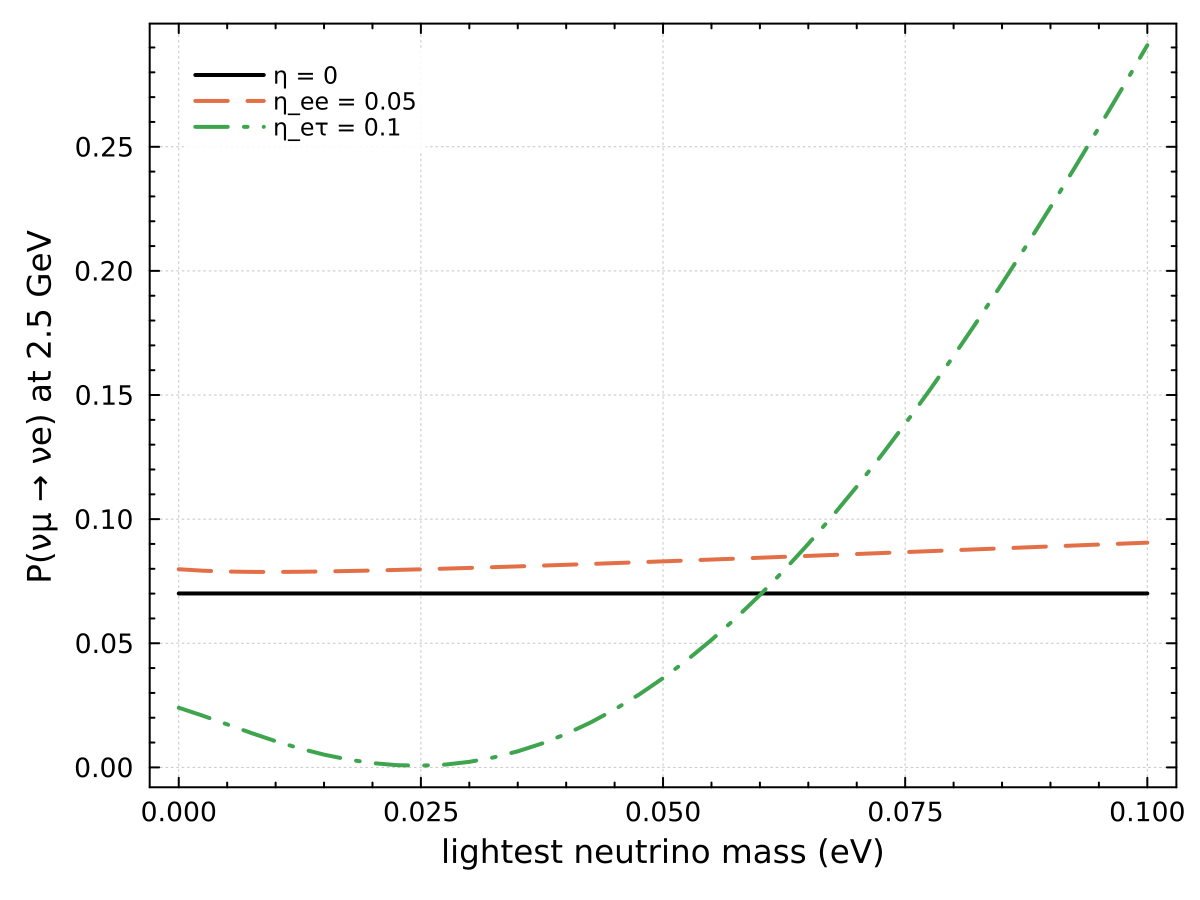

In [6]:
mℓ = range(0, 0.1, 41)   # eV
P(x) = probability(x, :μ, :e; E = [2.5], DUNE...)[1]
plot(mℓ, [P(OscParams(sm; m_lightest = m)) for m in mℓ]; label = "η = 0", xlabel = "lightest neutrino mass (eV)", ylabel = "P(νμ → νe) at 2.5 GeV", color = :black)
plot!(mℓ, [P(OscParams(ηee; m_lightest = m)) for m in mℓ]; label = "η_ee = 0.05", linestyle = :dash)
plot!(mℓ, [P(OscParams(ηeτ; m_lightest = m)) for m in mℓ]; label = "η_eτ = 0.1", linestyle = :dashdot)

The η = 0 line is flat, as it should be. With scalar NSI, the appearance probability at DUNE changes noticeably between a massless lightest neutrino and 0.1 eV. Scalar NSI would make long-baseline experiments sensitive to the mass scale.

## Scalar NSI look like standard oscillations

Here is a less obvious property. In this package η is a fixed number, the value appropriate for the matter along the baseline. With a fixed η, $(M + \delta M)(M + \delta M)^\dagger$ is just another Hermitian matrix, so it can be diagonalised as $U'\,\mathrm{diag}(m'^2_1, m'^2_2, m'^2_3)\,U'^\dagger$. A scalar NSI model is therefore *exactly* a standard model with different mixing angles, phase and mass splittings:

In [7]:
function effective_vacuum(q)
    U = pmns_matrix(q)
    δM = sqrt(abs(q.Δm31)) * [q.η_ee            q.η_eμ * cis(q.δ_eμ)  q.η_eτ * cis(q.δ_eτ)
                              q.η_eμ * cis(-q.δ_eμ)  0                     0
                              q.η_eτ * cis(-q.δ_eτ)  0                     0]
    M = U * Diagonal(light_masses(q; lightest = q.m_lightest)) * U' + δM
    F = eigen(Hermitian(M * M'))
    θ12, θ13, θ23, δ = GLoBES.mixing_angles(F.vectors)   # PDG angles of the eigenvectors
    return OscParams(θ12 = θ12, θ13 = θ13, θ23 = θ23, δ = δ, Δm21 = F.values[2] - F.values[1], Δm31 = F.values[3] - F.values[1])
end

q = OscParams(model, p; η_ee = 0.02, η_eτ = 0.03, δ_eτ = 1.0, m_lightest = 0.03)
look_alike = effective_vacuum(q)
[(name = n, true_value = round(f(p); sigdigits = 4), looks_like = round(f(look_alike); sigdigits = 4)) for (n, f) in
 ("sin²θ12" => x -> sin(x.θ12)^2, "sin²θ13" => x -> sin(x.θ13)^2, "sin²θ23" => x -> sin(x.θ23)^2, "δ (°)" => x -> rad2deg(x.δ), "Δm²21 (eV²)" => x -> x.Δm21, "Δm²31 (eV²)" => x -> x.Δm31)]

6-element Vector{@NamedTuple{name::String, true_value::Float64, looks_like::Float64}}:
 (name = "sin²θ12", true_value = 0.3088, looks_like = 0.6387)
 (name = "sin²θ13", true_value = 0.02249, looks_like = 0.02456)
 (name = "sin²θ23", true_value = 0.47, looks_like = 0.4694)
 (name = "δ (°)", true_value = 207.0, looks_like = 133.1)
 (name = "Δm²21 (eV²)", true_value = 7.537e-5, looks_like = 0.0001116)
 (name = "Δm²31 (eV²)", true_value = 0.002521, looks_like = 0.002513)

In [8]:
with_η = [probability(q, :μ, β; E = collect(E), L = 1300, ρ = ρ) for β in (:e, :μ), ρ in (0.0, 2.848, 10.0)]
standard_engine!()
standard = [probability(look_alike, :μ, β; E = collect(E), L = 1300, ρ = ρ) for β in (:e, :μ), ρ in (0.0, 2.848, 10.0)]
use_model!(model)
maximum(maximum(abs, a .- b) for (a, b) in zip(with_η, standard))   # every energy, two channels, three densities

6.661338147750939e-15

Even couplings of a few percent move the solar parameters a lot. θ12 crosses into the "dark octant" (sin²θ12 > 0.5) and Δm²21 grows by half, because the solar splitting is the smallest scale in $M M^\dagger$ and δM competes with it directly. The atmospheric parameters barely move.

The probabilities of the two descriptions agree to machine precision at every energy and every density. A single experiment therefore cannot tell scalar NSI from a shift of the standard parameters. In reality η is proportional to the density of the matter the neutrinos cross. Scalar NSI show up as **disagreement between experiments** that measure the same parameters in different environments: reactors and long-baseline beams in the Earth's crust, solar neutrinos in the Sun's core. To model that, give each experiment the η that matches its density.

## Agreement with the C engine

The package tests against the C engine of the scalar-NSI and decoherence study of DUNE (`snsi_engine_ihfix.c`). The reference values ship with the package, in `test/snsi_c_reference.txt`: NuFIT 6.1 with η_eμ = 0.05, δ_eμ = 1 at 1300 km.

In [9]:
ref = [parse.(Float64, split(l)) for l in eachline(joinpath(pkgdir(NeutrinoScalarNSI), "test", "snsi_c_reference.txt")) if !startswith(l, "#")]
base = OscParams(θ12 = asin(sqrt(0.3088)), θ13 = asin(sqrt(0.02249)), θ23 = asin(sqrt(0.470)), δ = deg2rad(207), Δm21 = 7.537e-5, Δm31 = 2.521e-3)
c_engine = OscParams(model, base; η_eμ = 0.05, δ_eμ = 1.0)
julia_values = [probability(c_engine, :μ, :e; E = [Eν], DUNE..., antineutrino = cp < 0)[1] for (_, cp, Eν, _, _) in ref]
maximum(abs(j / r[4] - 1) for (j, r) in zip(julia_values, ref))   # largest relative difference

2.6911806116913795e-13

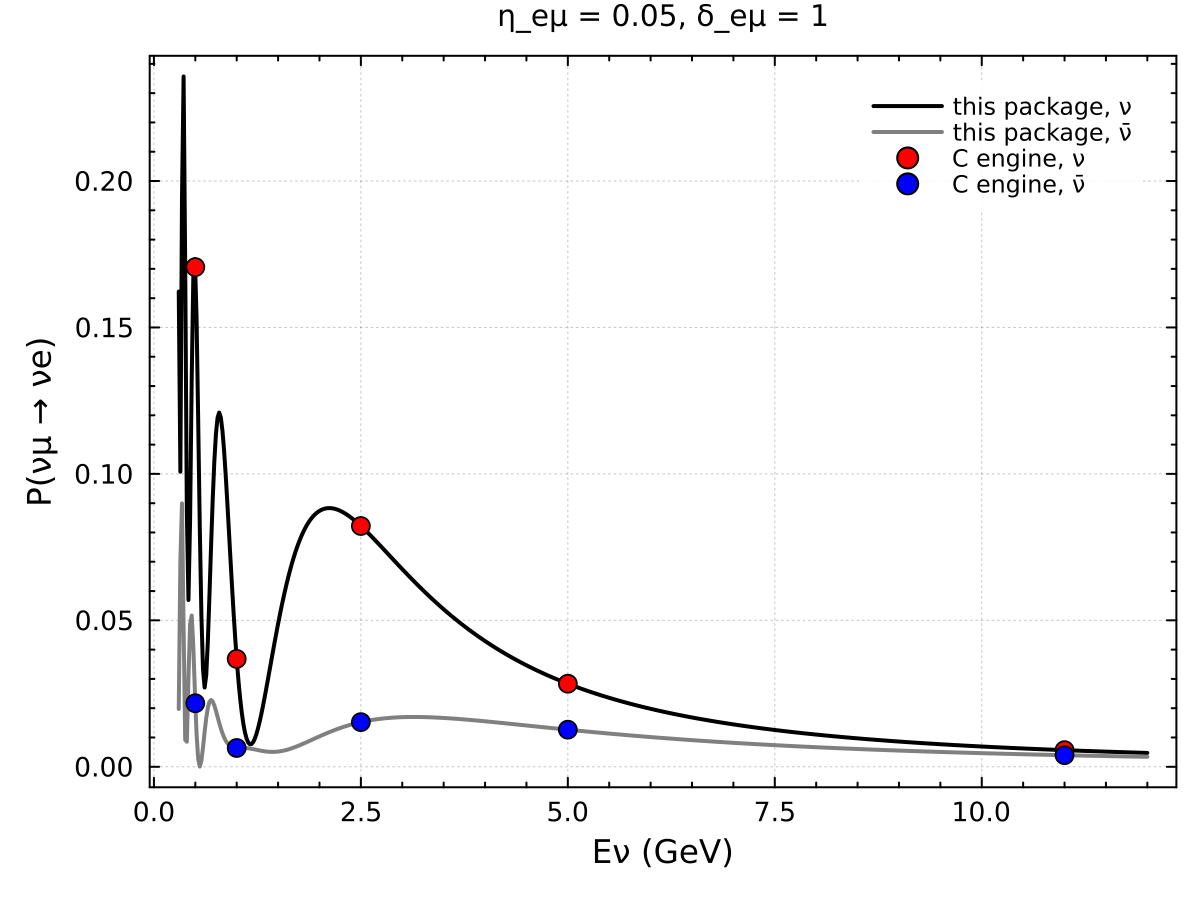

In [10]:
Ec = range(0.3, 12, 600)
plot_probability("this package, ν" => c_engine; E = Ec, DUNE..., ylabel = "P(νμ → νe)", title = "η_eμ = 0.05, δ_eμ = 1")
plot!(Ec, probability(c_engine, :μ, :e; E = collect(Ec), DUNE..., antineutrino = true); label = "this package, ν̄", color = :gray)
for (anti, colour) in ((false, :red), (true, :blue))
    rows = [r for r in ref if (r[2] < 0) == anti]
    scatter!([r[3] for r in rows], [r[4] for r in rows]; label = anti ? "C engine, ν̄" : "C engine, ν", color = colour, markersize = 5)
end
plot!()

## Event rates and the sensitivity of DUNE

The DUNE configuration of the Technical Design Report, 5 years each of neutrino and antineutrino running:

In [11]:
dune = Experiment(dune_configuration())   # the first time, this downloads the data tables from arXiv
running_time!(dune, 5.0)
for (label, x) in curves
    simulate!(x)
    println(rpad(label, 14), round.(Int, [sum(event_rates(dune; rule = r).signal) for r in 1:4]), "   (", join(rule_names(dune), ", "), ")")
end

SM            

[1591, 321, 15380, 8953]   (nue_app, nuebar_app, numu_dis, numubar_dis)
η_ee = 0.05   [1823, 355, 15360, 8951]   (nue_app, nuebar_app, numu_dis, numubar_dis)
η_eμ = 0.05   [1246, 202, 15454, 9024]   (nue_app, nuebar_app, numu_dis, numubar_dis)
η_eτ = 0.1    [542, 124, 15403, 8976]   (nue_app, nuebar_app, numu_dis, numubar_dis)


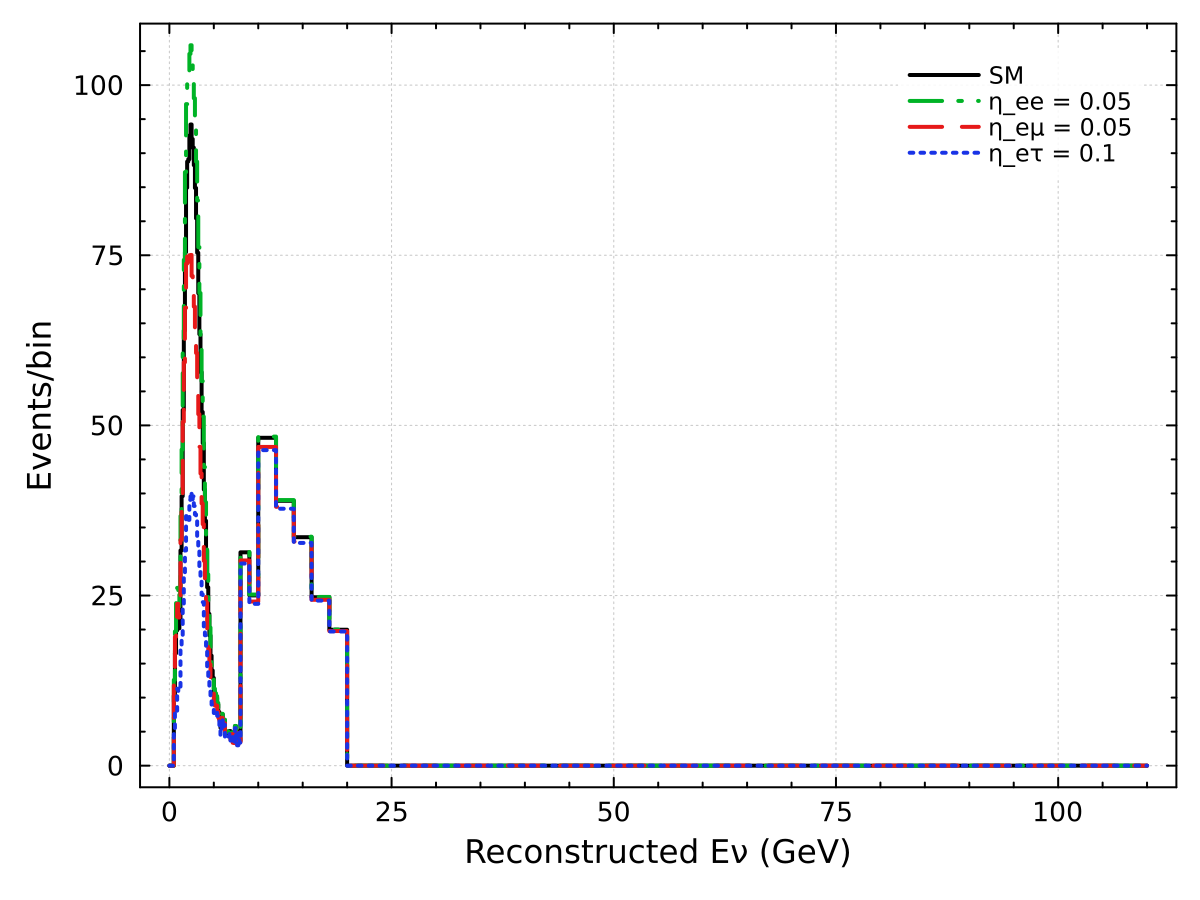

In [12]:
plot_events(dune, curves...; rule = 1)   # νe appearance

Δχ² of η_ee when the data have no new physics. Because η mimics the standard parameters, fitting θ13, θ23, δ and Δm²31 absorbs much of its effect. Each fitted point takes about half a minute.

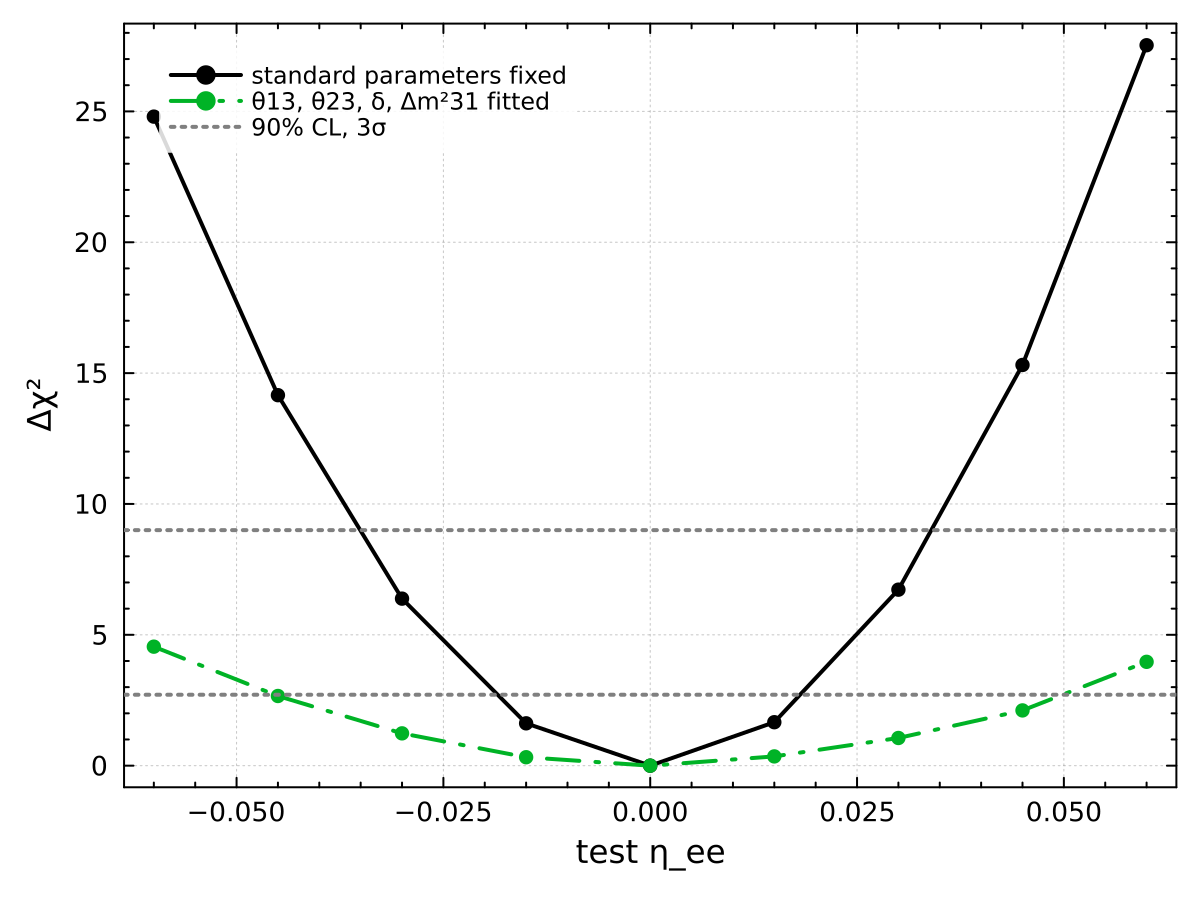

In [13]:
ηs = range(-0.06, 0.06, 9)
fixed = chi2_profile(sm, :η_ee => ηs)
fitted = chi2_profile(sm, :η_ee => ηs; free = (:θ13, :θ23, :δ, :Δm31))
plot_curves(ηs, "standard parameters fixed" => fixed, "θ13, θ23, δ, Δm²31 fitted" => fitted; xlabel = "test η_ee", ylabel = "Δχ²", markers = true)
hline!([2.71, 9]; color = :gray, linestyle = :dot, label = "90% CL, 3σ")

In [14]:
standard_engine!()   # back to standard three-flavour oscillations